## Set up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import joblib
from PIL import Image
from scipy.ndimage import uniform_filter, gaussian_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

SEED = 42
rng = np.random.default_rng(SEED)

from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

PROCESSED = ROOT / "ml" / "processed"
MODEL_DIR = ROOT / "ml" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "dataset_splits.csv")

with open(PROCESSED / "preprocess_config.json") as f:
    config = json.load(f)

print("Project root:", ROOT)
print("Random Forest engine: Scikit-learn (CPU multi-threaded, n_jobs=-1)")
print("Dataset columns:", df.columns.tolist())
print("Configuration:", config)


Project root: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
Random Forest engine: Scikit-learn (CPU multi-threaded, n_jobs=-1)
Dataset columns: ['image_path', 'mask_path', 'split', 'hash', 'fg']
Configuration: {'seed': 42, 'img_size': [256, 256], 'mask_threshold': 127, 'batch_size': 8, 'mean': [0.42435854638949455, 0.42435854638949455, 0.42435854638949455], 'std': [0.21396083519354342, 0.21396083519354342, 0.21396083519354342], 'pos_weight': 3.008870415448105, 'counts': {'train': 6455, 'test': 808, 'val': 807}}


## 2. Train / Validation / Test Split

In [2]:
print(df["split"].value_counts())

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

split
train    6455
test      808
val       807
Name: count, dtype: int64
Training: 6455
Validation: 807
Testing: 808


## 3. Load Image and Mask

In [3]:
IMG_SIZE = (256, 256)
MASK_THRESHOLD = 127

def load_image_mask(row):
    image_path = ROOT / row["image_path"]
    mask_path = ROOT / row["mask_path"]

    image = Image.open(image_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    image = image.resize(IMG_SIZE, Image.Resampling.BILINEAR)
    mask = mask.resize(IMG_SIZE, Image.Resampling.NEAREST)

    image = np.asarray(image, dtype=np.float32) / 255.0
    mask = (np.asarray(mask) > MASK_THRESHOLD).astype(np.uint8)

    return image, mask

## 4. Feature Extraction

In [4]:
def extract_features(image):
    gray = (
        0.299 * image[:, :, 0]
        + 0.587 * image[:, :, 1]
        + 0.114 * image[:, :, 2]
    )

    local_mean = uniform_filter(gray, size=5)

    local_variance = uniform_filter(gray**2, size=5) - local_mean**2
    local_std = np.sqrt(np.maximum(local_variance, 0))

    smooth = gaussian_filter(gray, sigma=2)

    features = np.stack(
        [
            image[:, :, 0],
            image[:, :, 1],
            image[:, :, 2],
            gray,
            local_mean,
            local_std,
            smooth
        ],
        axis=-1
    )

    return features.reshape(-1, 7)

## 5. Build the Training Dataset

In [5]:
N_TRAIN_IMAGES = 200
PIXELS_PER_CLASS = 250

sampled_df = train_df.sample(
    n=min(N_TRAIN_IMAGES, len(train_df)),
    random_state=SEED
)

X_parts = []
y_parts = []

for _, row in sampled_df.iterrows():
    image, mask = load_image_mask(row)

    features = extract_features(image)
    labels = mask.reshape(-1)

    for cls in [0, 1]:
        indices = np.where(labels == cls)[0]

        if len(indices) == 0:
            continue

        chosen = rng.choice(
            indices,
            size=min(PIXELS_PER_CLASS, len(indices)),
            replace=False
        )

        X_parts.append(features[chosen])
        y_parts.append(labels[chosen])

X_train = np.vstack(X_parts).astype(np.float32)
y_train = np.concatenate(y_parts)

print("Training feature shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Class counts:", np.bincount(y_train))

Training feature shape: (97787, 7)
Training labels shape: (97787,)
Class counts: [49750 48037]


## 6. Train the Random Forest

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=SEED
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


## 7. Save the Model

In [7]:
model_path = MODEL_DIR / "random_forest.pkl"

joblib.dump(rf_model, model_path)

print("Model saved at:", model_path)

Model saved at: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\ml\models\random_forest.pkl


## 8. Prediction Function

In [8]:
def predict_mask(image, model):
    features = extract_features(image)

    predictions = model.predict(features)

    return predictions.reshape(image.shape[:2]).astype(np.uint8)

## 9. Evaluation Metrics

In [9]:
def calculate_metrics(actual, predicted):
    actual = actual.astype(bool)
    predicted = predicted.astype(bool)

    intersection = np.logical_and(actual, predicted).sum()
    actual_sum = actual.sum()
    predicted_sum = predicted.sum()

    dice = (2 * intersection + 1e-7) / (
        actual_sum + predicted_sum + 1e-7
    )

    union = np.logical_or(actual, predicted).sum()

    iou = (intersection + 1e-7) / (union + 1e-7)

    return dice, iou

## 10. Evaluate on the Test Set

In [10]:
total_intersection = 0
total_actual = 0
total_predicted = 0
total_union = 0

for i, (_, row) in enumerate(test_df.iterrows(), start=1):
    image, actual = load_image_mask(row)
    predicted = predict_mask(image, rf_model)

    actual_bool = actual.astype(bool)
    pred_bool = predicted.astype(bool)

    total_intersection += np.logical_and(
        actual_bool, pred_bool
    ).sum()

    total_union += np.logical_or(
        actual_bool, pred_bool
    ).sum()

    total_actual += actual_bool.sum()
    total_predicted += pred_bool.sum()

    if i % 100 == 0:
        print(f"Evaluated {i}/{len(test_df)} images")

test_dice = (
    (2 * total_intersection + 1e-7)
    / (total_actual + total_predicted + 1e-7)
)

test_iou = (
    (total_intersection + 1e-7)
    / (total_union + 1e-7)
)

print("\nRandom Forest Final Test Results")
print(f"Dice Score: {test_dice:.4f}")
print(f"IoU Score: {test_iou:.4f}")

Evaluated 100/808 images
Evaluated 200/808 images
Evaluated 300/808 images
Evaluated 400/808 images
Evaluated 500/808 images
Evaluated 600/808 images
Evaluated 700/808 images
Evaluated 800/808 images

Random Forest Final Test Results
Dice Score: 0.6990
IoU Score: 0.5372


## 11. Visualize a Prediction

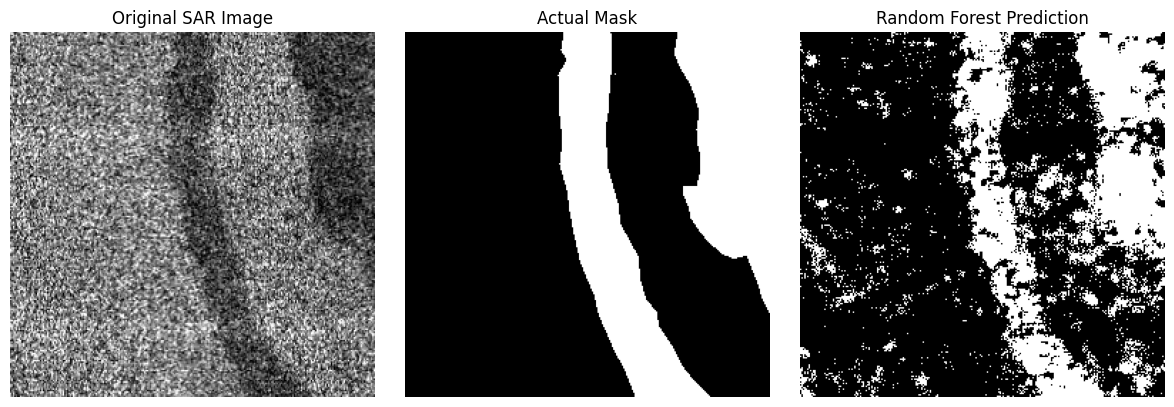

In [11]:
row = test_df.iloc[0]

image, actual_mask = load_image_mask(row)
predicted_mask = predict_mask(image, rf_model)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title("Original SAR Image")

axes[1].imshow(actual_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Actual Mask")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Random Forest Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()